# T25 · Interpretação do modelo final com SHAP

**Issue:** #25 · **Fase 4 · Avaliação e Interpretação** · **Modelo:** o modelo final da T23 (`models/final_model.joblib`)

**O que é o SHAP, em linguagem clínica:** para cada paciente, o modelo parte do **risco médio** da população e cada
característica (pressão, idade, colesterol...) **empurra esse risco para cima ou para baixo**. O SHAP mede o tamanho
desse empurrão. Assim dá para responder duas perguntas:

- **No geral:** quais fatores mais pesam nas decisões do modelo, e em que direção?
- **Para cada paciente:** por que o modelo classificou *este* paciente como alto ou baixo risco?

> Os valores SHAP estão na escala interna do modelo (*log-odds*): **positivo aumenta** a chance de doença, **negativo
> diminui**, e 0 é neutro. As funções estão em `cardio.models.explain`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from cardio.config import FIGURES_DIR
from cardio.data.preprocessing import load_splits
from cardio.models.explain import (
    plot_shap_dependence, plot_shap_summary, plot_shap_waterfall, probabilidade, shap_por_faixa, shap_values,
)
from cardio.models.final_model import FINAL_MODEL_PATH, train_final_model


def pct(valor: float, casas: int = 0) -> str:
    return f"{valor * 100:.{casas}f}%".replace(".", ",")


def num(valor: float, casas: int = 2) -> str:
    return f"{valor:.{casas}f}".replace(".", ",")


def texto(conteudo: str) -> None:
    display(Markdown(conteudo))


def mostrar(caminho: Path) -> None:
    display(Image(filename=str(caminho)))

## 1. Modelo final e amostra de pacientes

O modelo final (treinado na T23) é carregado de `models/final_model.joblib`; se o arquivo não existir (ele não é
versionado no Git), é treinado de novo com `train_final_model()`. O SHAP é calculado numa **amostra de 1.500 pacientes da
validação**, como pede a issue: no dataset inteiro seria mais lento e a interpretação não muda.

> **Atenção:** o modelo final foi treinado com treino + validação, então esses pacientes fazem parte do que ele viu.
> Isso não é problema aqui: o SHAP explica **como o modelo decide**, não mede o desempenho dele (que foi medido no teste, na T23).

In [2]:
if not FINAL_MODEL_PATH.exists():
    train_final_model()
artefato = joblib.load(FINAL_MODEL_PATH)
pipeline, limiar = artefato["model"], artefato["threshold"]

_, X_val, _, _, y_val, _ = load_splits(artefato["features"], save_ids=False)
explicacao, X_amostra = shap_values(pipeline, X_val, sample_size=1500)
y_amostra = y_val.loc[X_amostra.index]
proba = pipeline.predict_proba(X_amostra)[:, 1]
previsto = (proba >= limiar).astype(int)

risco_base = probabilidade(explicacao.base_values[0])
print(f"Modelo: {artefato['modelo']} (conjunto {artefato['features']}), limiar {limiar}")
print(f"Amostra: {len(X_amostra)} pacientes, {pct(y_amostra.mean())} com doença")
print(f"Risco de partida do modelo (valor-base): {pct(risco_base, 1)}")

Modelo: xgb (conjunto A), limiar 0.36
Amostra: 1500 pacientes, 51% com doença
Risco de partida do modelo (valor-base): 49,5%


## 2. Visão geral: o que mais pesa nas decisões (summary plot)

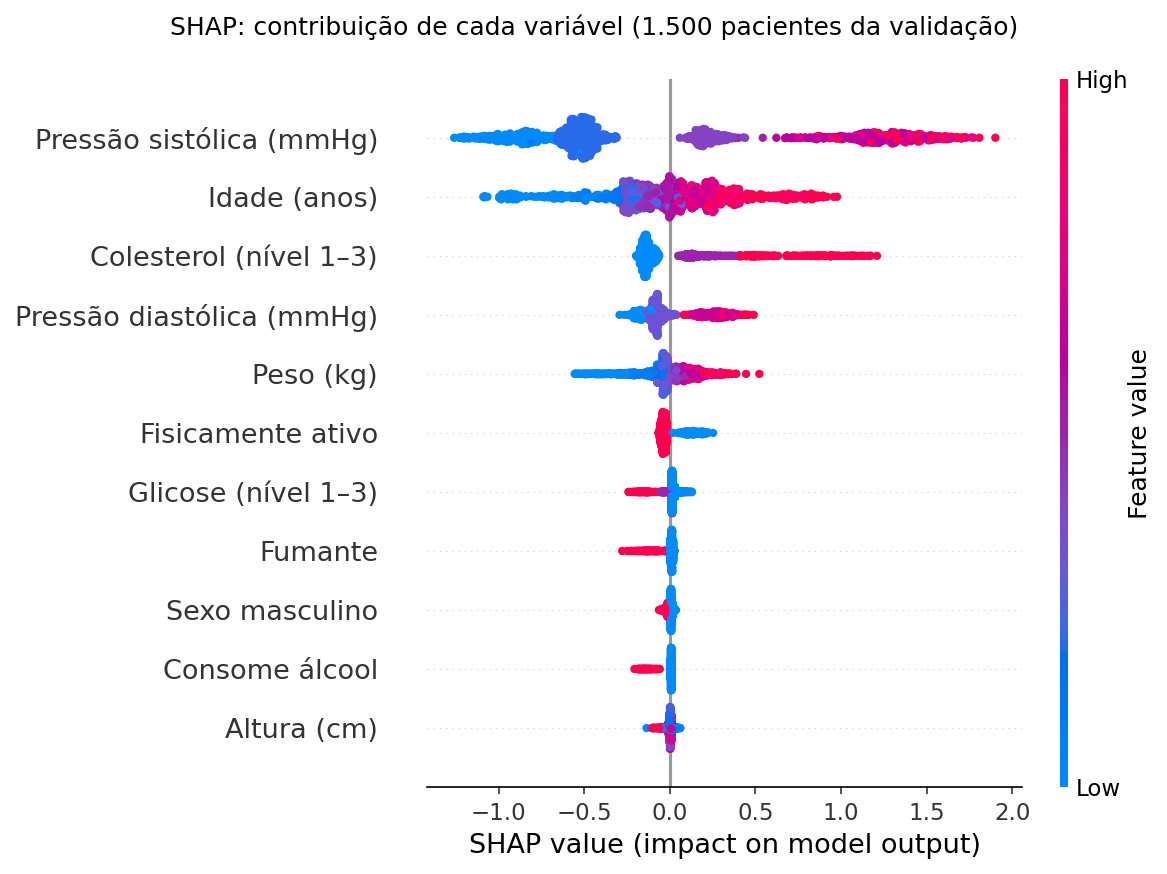

,contribuicao_media_absoluta
Pressão sistólica (mmHg),0.756
Idade (anos),0.272
Colesterol (nível 1–3),0.209
Pressão diastólica (mmHg),0.149
Peso (kg),0.104
Fisicamente ativo,0.057
Glicose (nível 1–3),0.030
Fumante,0.020
Sexo masculino,0.015
Consome álcool,0.015


In [3]:
caminho = plot_shap_summary(explicacao, FIGURES_DIR / "t25_shap_summary.png",
                            "SHAP: contribuição de cada variável (1.500 pacientes da validação)")
mostrar(caminho)

importancia = (pd.Series(np.abs(explicacao.values).mean(axis=0), index=explicacao.feature_names)
               .sort_values(ascending=False).rename("contribuicao_media_absoluta"))
importancia.round(3).to_frame()

In [4]:
top = importancia.index.tolist()
participacao = importancia / importancia.sum()
texto(f"""**Como ler o gráfico:** cada ponto é um paciente. A posição no eixo horizontal mostra se a variável **aumentou**
(à direita do zero) ou **diminuiu** (à esquerda) o risco daquele paciente; a cor mostra o valor da variável (**vermelho = alto**,
**azul = baixo**). As variáveis estão em ordem de importância.

**Interpretação:**
- **{top[0]}** é, de longe, o fator mais importante: responde por **{pct(participacao.iloc[0])}** de toda a contribuição
  do modelo. Os pontos vermelhos (pressão alta) ficam à direita: pressão alta aumenta muito o risco; pressão baixa (azul) reduz.
- Em seguida vêm **{top[1]}** ({pct(participacao.iloc[1])}) e **{top[2]}** ({pct(participacao.iloc[2])}): pacientes mais
  velhos e com colesterol alto têm risco maior.
- Juntos, os **três primeiros fatores respondem por {pct(participacao.iloc[:3].sum())}** das decisões.
- Hábitos autodeclarados (fumo, álcool e atividade física), altura e sexo têm peso pequeno.

Isso é **clinicamente coerente**: pressão arterial, idade e colesterol são os fatores de risco cardiovascular clássicos,
e é a mesma ordem vista na correlação (T07) e nos *odds ratios* da Regressão Logística (T15).""")

**Como ler o gráfico:** cada ponto é um paciente. A posição no eixo horizontal mostra se a variável **aumentou**
(à direita do zero) ou **diminuiu** (à esquerda) o risco daquele paciente; a cor mostra o valor da variável (**vermelho = alto**,
**azul = baixo**). As variáveis estão em ordem de importância.

**Interpretação:**
- **Pressão sistólica (mmHg)** é, de longe, o fator mais importante: responde por **46%** de toda a contribuição
  do modelo. Os pontos vermelhos (pressão alta) ficam à direita: pressão alta aumenta muito o risco; pressão baixa (azul) reduz.
- Em seguida vêm **Idade (anos)** (17%) e **Colesterol (nível 1–3)** (13%): pacientes mais
  velhos e com colesterol alto têm risco maior.
- Juntos, os **três primeiros fatores respondem por 76%** das decisões.
- Hábitos autodeclarados (fumo, álcool e atividade física), altura e sexo têm peso pequeno.

Isso é **clinicamente coerente**: pressão arterial, idade e colesterol são os fatores de risco cardiovascular clássicos,
e é a mesma ordem vista na correlação (T07) e nos *odds ratios* da Regressão Logística (T15).

## 3. A partir de que valor o risco sobe? (dependence plots)

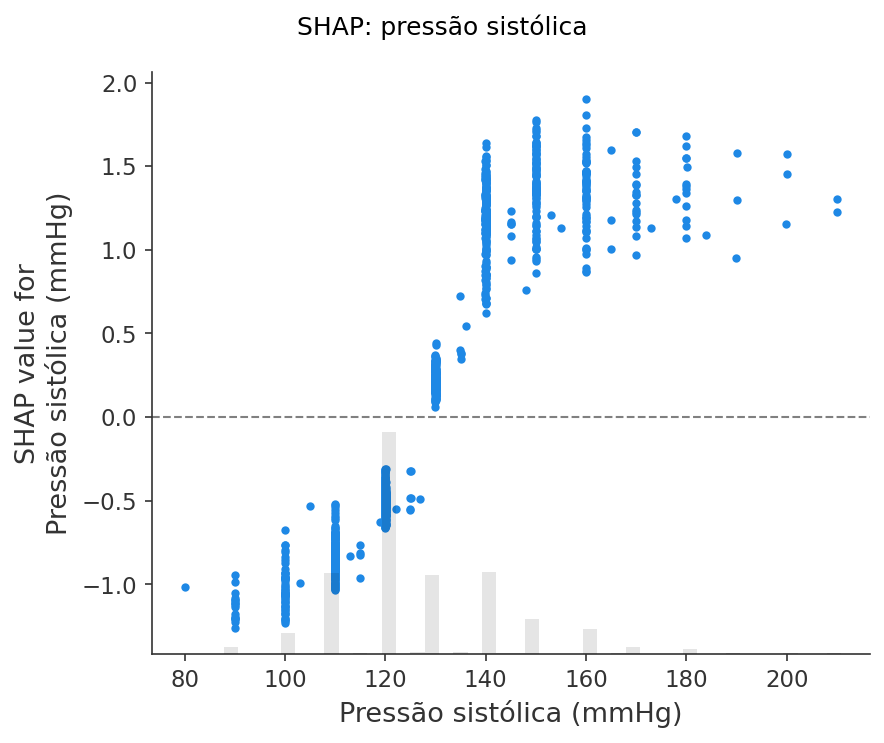

,faixa,pacientes,shap_medio
0,"[0, 110)",75,-1.041
1,"[110, 120)",216,-0.836
2,"[120, 130)",580,-0.512
3,"[130, 140)",209,0.227
4,"[140, 150)",218,1.178
5,"[150, 160)",92,1.373
6,"[160, 180)",88,1.344
7,"[180, 251)",22,1.348


In [5]:
caminho = plot_shap_dependence(explicacao, "Pressão sistólica (mmHg)", FIGURES_DIR / "t25_shap_dependencia_pressao.png",
                               "SHAP: pressão sistólica")
mostrar(caminho)
faixas_pressao = shap_por_faixa(explicacao, "Pressão sistólica (mmHg)", [0, 110, 120, 130, 140, 150, 160, 180, 251])
faixas_pressao.round(3)

In [6]:
def primeira_faixa_de_risco(tabela: pd.DataFrame) -> str:
    """Primeira faixa (com pelo menos 20 pacientes) em que a contribuição média passa a aumentar o risco."""
    positivas = tabela[(tabela["shap_medio"] > 0) & (tabela["pacientes"] >= 20)]
    return positivas["faixa"].iloc[0] if not positivas.empty else None


faixa_p = primeira_faixa_de_risco(faixas_pressao)
p = faixas_pressao.set_index("faixa")["shap_medio"]
texto(f"""**Interpretação:** abaixo de **{int(faixa_p.left)} mmHg** a pressão sistólica **reduz** o risco (contribuição média de
{num(p.iloc[0])} na faixa mais baixa). A partir de **{int(faixa_p.left)} mmHg** ela passa a **aumentar** o risco, e o efeito cresce
rápido até cerca de 150 mmHg; acima disso praticamente se estabiliza (contribuição média em torno de {num(p.iloc[-3:].mean())}).

Em termos de probabilidade, para um paciente com o risco médio de partida ({pct(risco_base)}), só a pressão levaria o risco a
cerca de **{pct(probabilidade(explicacao.base_values[0] + p.iloc[0]))}** com menos de 110 mmHg e a cerca de
**{pct(probabilidade(explicacao.base_values[0] + p.iloc[-3:].mean()))}** com 150 mmHg ou mais.

O ponto de virada coincide com o limite de **hipertensão estágio 1 da diretriz ACC/AHA (130 mmHg)**: o modelo aprendeu
sozinho, a partir dos dados, o mesmo corte usado na prática clínica.""")

**Interpretação:** abaixo de **130 mmHg** a pressão sistólica **reduz** o risco (contribuição média de
-1,04 na faixa mais baixa). A partir de **130 mmHg** ela passa a **aumentar** o risco, e o efeito cresce
rápido até cerca de 150 mmHg; acima disso praticamente se estabiliza (contribuição média em torno de 1,35).

Em termos de probabilidade, para um paciente com o risco médio de partida (49%), só a pressão levaria o risco a
cerca de **26%** com menos de 110 mmHg e a cerca de
**79%** com 150 mmHg ou mais.

O ponto de virada coincide com o limite de **hipertensão estágio 1 da diretriz ACC/AHA (130 mmHg)**: o modelo aprendeu
sozinho, a partir dos dados, o mesmo corte usado na prática clínica.

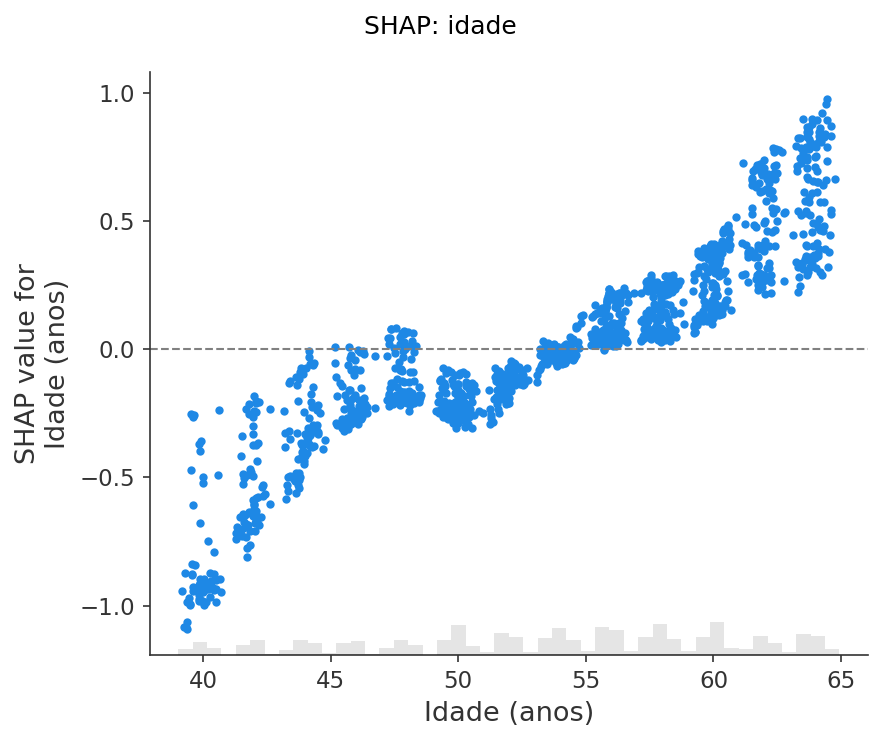

,faixa,pacientes,shap_medio
0,"[0, 40)",39,-0.807
1,"[40, 45)",182,-0.495
2,"[45, 50)",239,-0.172
3,"[50, 55)",335,-0.092
4,"[55, 60)",411,0.165
5,"[60, 70)",294,0.487


In [7]:
caminho = plot_shap_dependence(explicacao, "Idade (anos)", FIGURES_DIR / "t25_shap_dependencia_idade.png", "SHAP: idade")
mostrar(caminho)
faixas_idade = shap_por_faixa(explicacao, "Idade (anos)", [0, 40, 45, 50, 55, 60, 70])
faixas_idade.round(3)

In [8]:
faixa_i = primeira_faixa_de_risco(faixas_idade)
i = faixas_idade.set_index("faixa")["shap_medio"]
texto(f"""**Interpretação:** a idade age de forma **gradual e contínua**: abaixo de 40 anos ela reduz bastante o risco
(contribuição média de {num(i.iloc[0])}), o efeito protetor diminui a cada faixa, e a partir de **{int(faixa_i.left)} anos** ela passa a
**aumentar** o risco, chegando a {num(i.iloc[-1])} entre 60 e 65 anos. Diferente da pressão, não há um corte brusco: o risco
sobe aos poucos com o envelhecimento, como esperado clinicamente.""")

**Interpretação:** a idade age de forma **gradual e contínua**: abaixo de 40 anos ela reduz bastante o risco
(contribuição média de -0,81), o efeito protetor diminui a cada faixa, e a partir de **55 anos** ela passa a
**aumentar** o risco, chegando a 0,49 entre 60 e 65 anos. Diferente da pressão, não há um corte brusco: o risco
sobe aos poucos com o envelhecimento, como esperado clinicamente.

## 4. Pacientes individuais (waterfall plots)

Três pacientes da amostra, classificados com o limiar do modelo final (o mesmo da T22):
- um **acerto com doença** (doente corretamente sinalizado);
- um **acerto sem doença** (saudável corretamente não sinalizado);
- um **erro**: um doente que o modelo **não sinalizou** (falso negativo), o erro mais grave numa triagem.

**Como ler:** o gráfico começa no risco médio, embaixo (`E[f(X)]`), e cada barra mostra quanto uma característica do paciente
empurrou o risco para cima (vermelho) ou para baixo (azul), até chegar na previsão final dele, no topo (`f(x)`).

In [9]:
def escolher(mascara: np.ndarray, alvo: float) -> int:
    """Posição (na amostra) do paciente do grupo cuja probabilidade é mais próxima de ``alvo``."""
    posicoes = np.flatnonzero(mascara)
    return int(posicoes[np.argmin(np.abs(proba[posicoes] - alvo))])


real = y_amostra.to_numpy()
pacientes = {
    "Acerto com doença": escolher((real == 1) & (previsto == 1), 0.80),
    "Acerto sem doença": escolher((real == 0) & (previsto == 0), 0.15),
    "Erro: doente não sinalizado": escolher((real == 1) & (previsto == 0), 0.25),
}
COLUNAS = ["age_years", "sex_male", "height", "weight", "ap_hi", "ap_lo", "cholesterol", "gluc", "smoke", "alco", "active"]
fichas = X_amostra.iloc[list(pacientes.values())][COLUNAS].round(1)
fichas.insert(0, "caso", list(pacientes))
fichas["doença real"] = real[list(pacientes.values())]
fichas["probabilidade prevista"] = proba[list(pacientes.values())].round(2)
fichas.reset_index()

,id,caso,age_years,sex_male,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,doença real,probabilidade prevista
0,64357,Acerto com doença,50.7,0,167,65.0,170,80,1,1,0,0,1,1,0.80
1,97585,Acerto sem doença,44.0,0,177,64.0,110,80,1,1,0,0,1,0,0.15
2,57097,Erro: doente não sinalizado,48.5,0,158,64.0,120,80,1,1,0,0,1,1,0.25


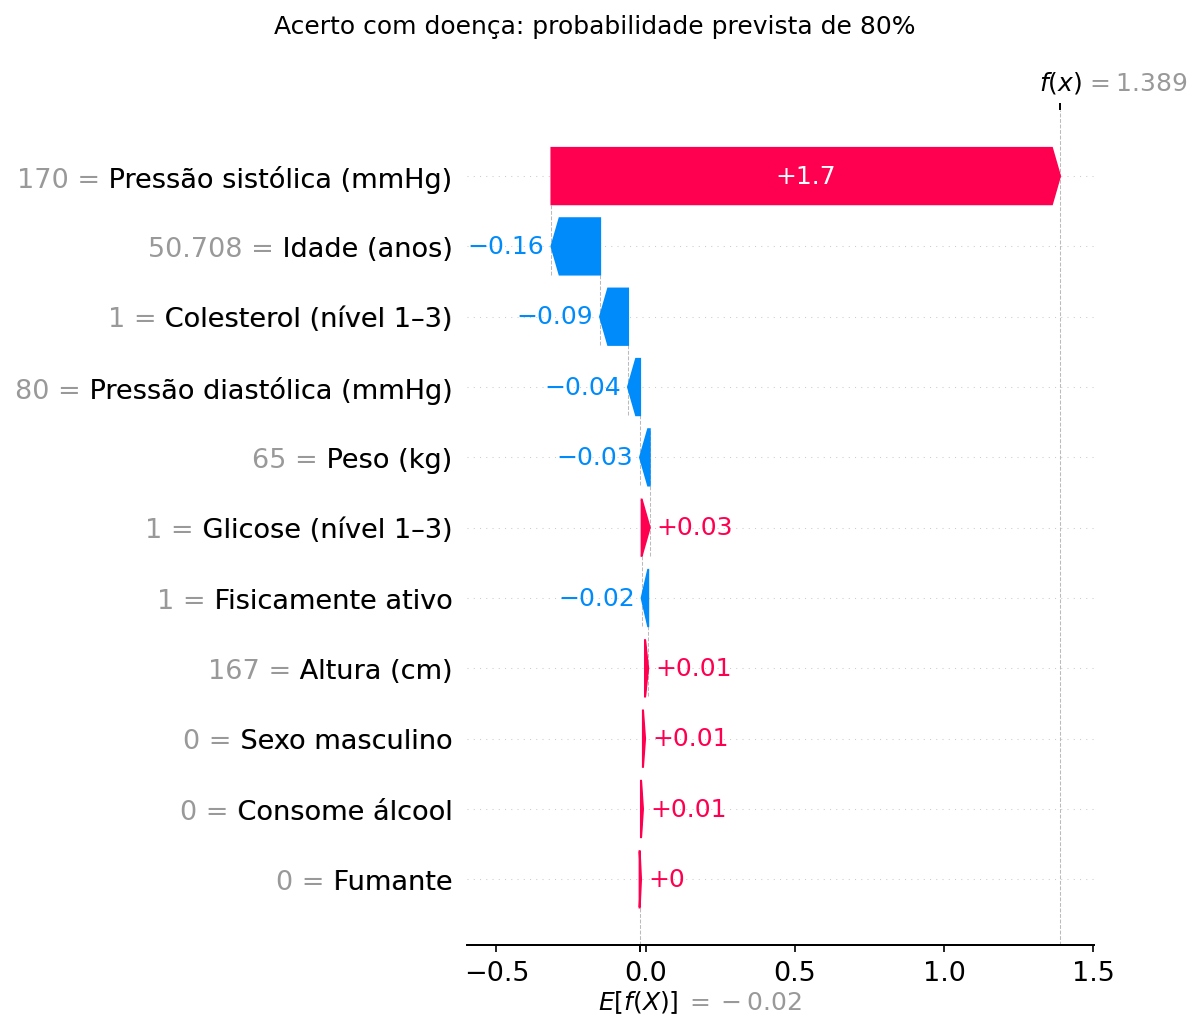

**Acerto com doença** (probabilidade prevista de **80%**, limiar 0,36). Os fatores que mais pesaram: **Pressão sistólica (mmHg) = 170** (aumentou o risco, 1,70); **Idade (anos) = 51** (reduziu o risco, -0,16); **Colesterol (nível 1–3) = 1** (reduziu o risco, -0,09).

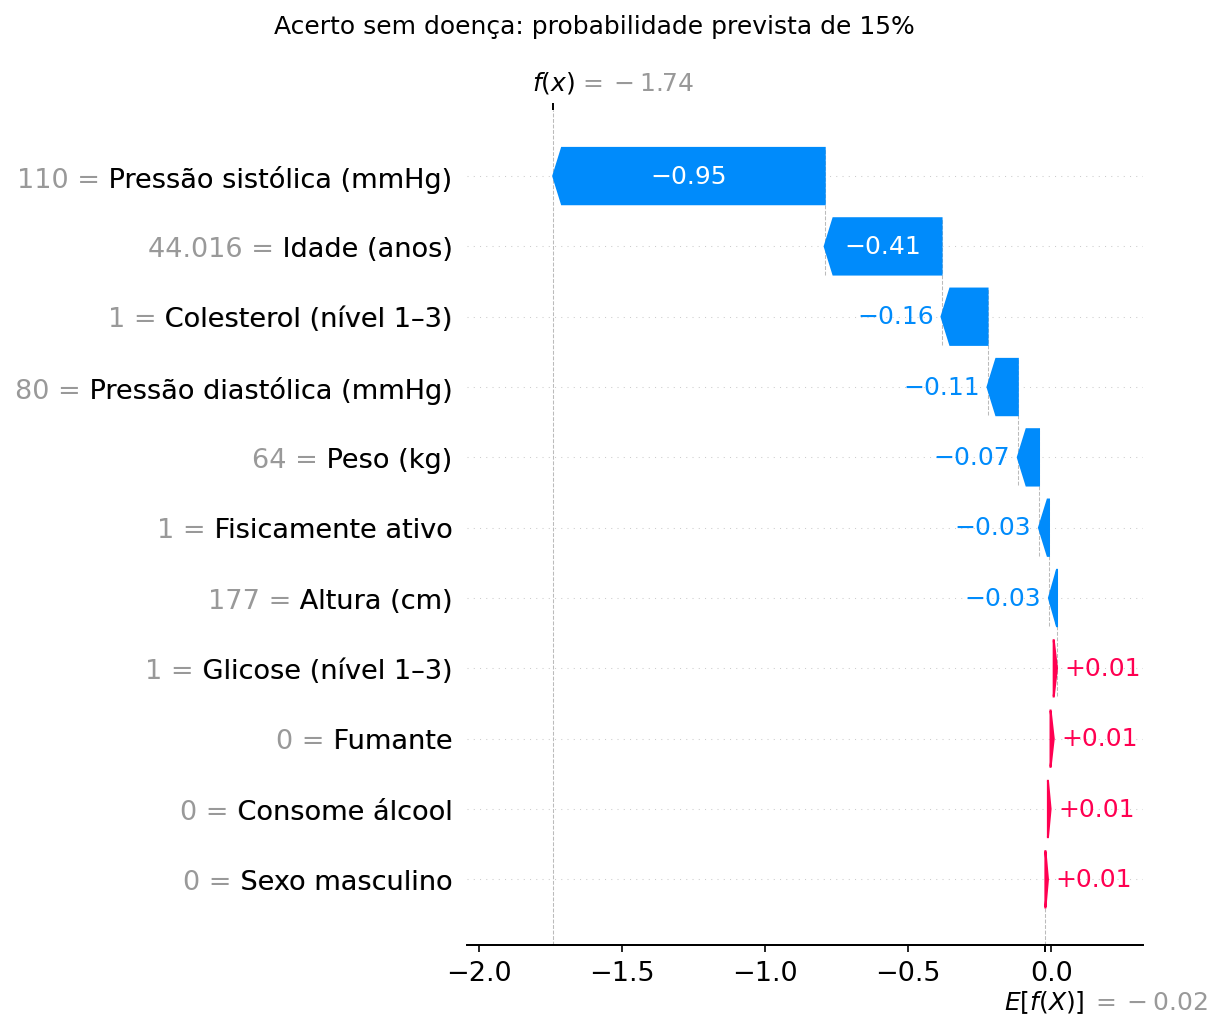

**Acerto sem doença** (probabilidade prevista de **15%**, limiar 0,36). Os fatores que mais pesaram: **Pressão sistólica (mmHg) = 110** (reduziu o risco, -0,95); **Idade (anos) = 44** (reduziu o risco, -0,41); **Colesterol (nível 1–3) = 1** (reduziu o risco, -0,16).

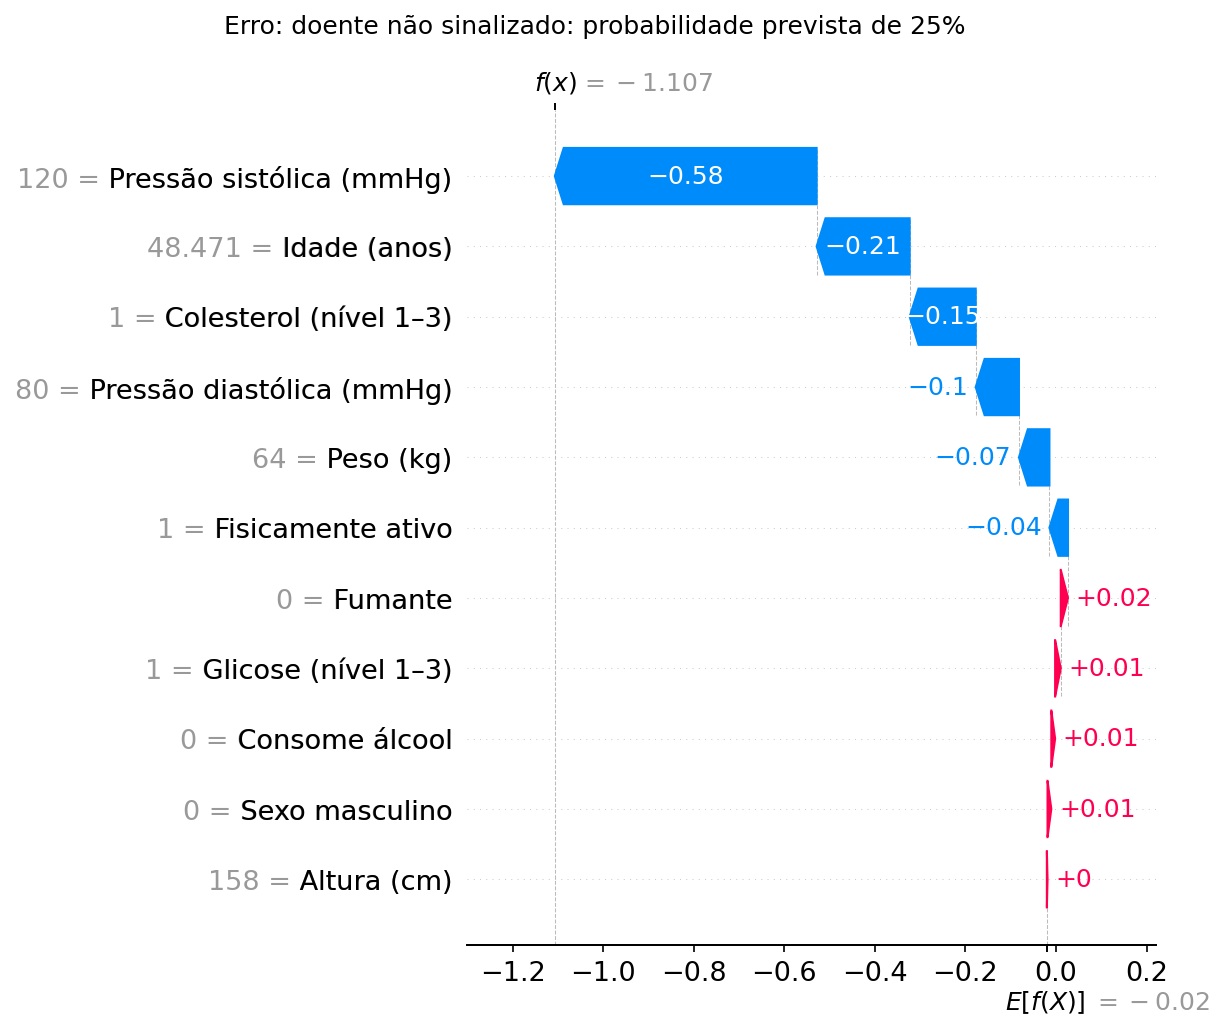

**Erro: doente não sinalizado** (probabilidade prevista de **25%**, limiar 0,36). Os fatores que mais pesaram: **Pressão sistólica (mmHg) = 120** (reduziu o risco, -0,58); **Idade (anos) = 48** (reduziu o risco, -0,21); **Colesterol (nível 1–3) = 1** (reduziu o risco, -0,15).

In [10]:
def resumo_paciente(posicao: int, n: int = 3) -> str:
    contrib = pd.Series(explicacao.values[posicao], index=explicacao.feature_names)
    valores = pd.Series(explicacao.data[posicao], index=explicacao.feature_names)
    partes = []
    for nome in contrib.abs().sort_values(ascending=False).index[:n]:
        direcao = "aumentou" if contrib[nome] > 0 else "reduziu"
        partes.append(f"**{nome} = {num(valores[nome], 0)}** ({direcao} o risco, {num(contrib[nome])})")
    return "; ".join(partes)


arquivos = {"Acerto com doença": "t25_shap_waterfall_acerto_doente.png",
            "Acerto sem doença": "t25_shap_waterfall_acerto_saudavel.png",
            "Erro: doente não sinalizado": "t25_shap_waterfall_erro.png"}
for caso, posicao in pacientes.items():
    caminho = plot_shap_waterfall(explicacao, posicao, FIGURES_DIR / arquivos[caso],
                                  f"{caso}: probabilidade prevista de {pct(proba[posicao])}")
    mostrar(caminho)
    texto(f"**{caso}** (probabilidade prevista de **{pct(proba[posicao])}**, limiar {num(limiar)}). "
          f"Os fatores que mais pesaram: {resumo_paciente(posicao)}.")

In [11]:
erro = pacientes["Erro: doente não sinalizado"]
texto(f"""**Por que o modelo errou no terceiro caso?** O paciente tem doença cardiovascular, mas as medidas que o modelo usa
(principalmente a pressão) parecem as de um paciente de baixo risco, e a probabilidade final ({pct(proba[erro])}) ficou abaixo do
limiar de {num(limiar)}. O modelo só enxerga as 11 variáveis do dataset: não sabe, por exemplo, o histórico familiar, o valor
exato do colesterol ou se o paciente já usa remédio para pressão (o que deixaria a pressão medida "normal").

Esse tipo de caso é a razão de o modelo ser usado **apenas como apoio à triagem**: o waterfall mostra ao médico *por que* o
paciente recebeu aquela pontuação, e o médico pode discordar com base no que o modelo não vê. **A decisão final é sempre do
médico.**""")

**Por que o modelo errou no terceiro caso?** O paciente tem doença cardiovascular, mas as medidas que o modelo usa
(principalmente a pressão) parecem as de um paciente de baixo risco, e a probabilidade final (25%) ficou abaixo do
limiar de 0,36. O modelo só enxerga as 11 variáveis do dataset: não sabe, por exemplo, o histórico familiar, o valor
exato do colesterol ou se o paciente já usa remédio para pressão (o que deixaria a pressão medida "normal").

Esse tipo de caso é a razão de o modelo ser usado **apenas como apoio à triagem**: o waterfall mostra ao médico *por que* o
paciente recebeu aquela pontuação, e o médico pode discordar com base no que o modelo não vê. **A decisão final é sempre do
médico.**

## 5. Conclusões (para a T33 e a T34)

In [12]:
texto(f"""- O modelo decide principalmente por **{top[0].split(' (')[0].lower()}**, **{top[1].split(' (')[0].lower()}** e **{top[2].split(' (')[0].lower()}**,
  que respondem por {pct(participacao.iloc[:3].sum())} das contribuições. São os fatores de risco cardiovascular clássicos: o modelo
  aprendeu relações clinicamente coerentes, e não artefatos dos dados.
- O risco associado à pressão sistólica sobe a partir de **{int(faixa_p.left)} mmHg**, o mesmo corte de hipertensão das diretrizes; o da
  idade sobe de forma gradual e passa a pesar a favor da doença a partir de **{int(faixa_i.left)} anos**.
- Hábitos autodeclarados (fumo, álcool, atividade física) têm pouco peso, coerente com a correlação fraca vista na EDA (T06 e T07)
  e com a limitação de serem dados informados pelo próprio paciente.
- Os waterfall plots mostram que cada previsão pode ser **explicada ao médico**, inclusive os erros, o que é essencial para o uso
  como ferramenta de apoio à decisão.

Figuras salvas em `results/figures/` com o prefixo `t25_`.""")

- O modelo decide principalmente por **pressão sistólica**, **idade** e **colesterol**,
  que respondem por 76% das contribuições. São os fatores de risco cardiovascular clássicos: o modelo
  aprendeu relações clinicamente coerentes, e não artefatos dos dados.
- O risco associado à pressão sistólica sobe a partir de **130 mmHg**, o mesmo corte de hipertensão das diretrizes; o da
  idade sobe de forma gradual e passa a pesar a favor da doença a partir de **55 anos**.
- Hábitos autodeclarados (fumo, álcool, atividade física) têm pouco peso, coerente com a correlação fraca vista na EDA (T06 e T07)
  e com a limitação de serem dados informados pelo próprio paciente.
- Os waterfall plots mostram que cada previsão pode ser **explicada ao médico**, inclusive os erros, o que é essencial para o uso
  como ferramenta de apoio à decisão.

Figuras salvas em `results/figures/` com o prefixo `t25_`.